--- Evaluation Metrics (n_estimators=100) ---
MSE  : 7.8802
RMSE : 2.8072
MAE  : 2.0367
MAPE : 0.1109
R²   : 0.8925



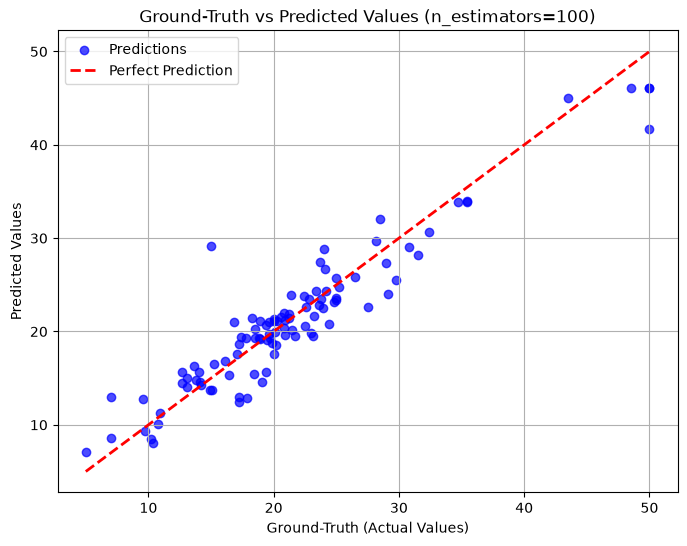

--- Comparison Table ---
 n_estimators  Test RMSE  Test R²
           50   2.747959 0.897029
          100   2.807172 0.892543
          200   2.931559 0.882809



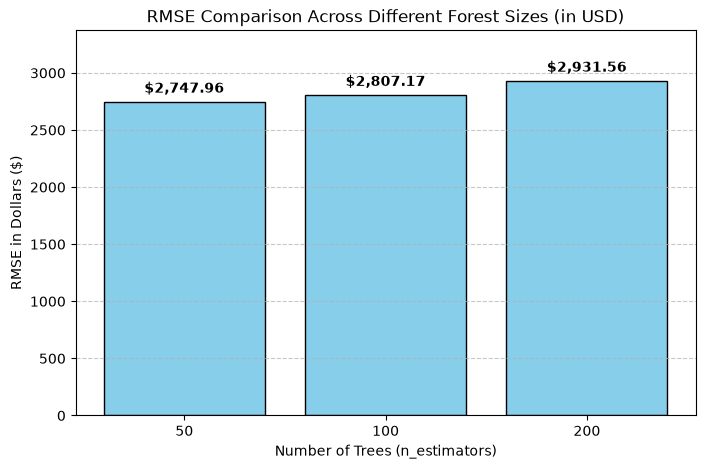

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

# ==========================================
# Part A: Load Boston Dataset & Split Data
# ==========================================

data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
y = raw_df.values[1::2, 2]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==========================================
# Part B: Train Random Forest (n_estimators=100)
# ==========================================
rf_100 = RandomForestRegressor(n_estimators=100, random_state=42)
rf_100.fit(X_train, y_train)
y_pred_100 = rf_100.predict(X_test)

# ==========================================
# Part C: Evaluate Model Metrics
# ==========================================
mse = mean_squared_error(y_test, y_pred_100)
rmse = np.sqrt(mse) 
mae = mean_absolute_error(y_test, y_pred_100)
mape = mean_absolute_percentage_error(y_test, y_pred_100)
r2 = r2_score(y_test, y_pred_100)

print("--- Evaluation Metrics (n_estimators=100) ---")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"MAPE : {mape:.4f}")
print(f"R²   : {r2:.4f}\n")

# ==========================================
# Part D: Plot Ground-Truth vs Predicted Values
# ==========================================
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_100, alpha=0.7, color='blue', label='Predictions')

min_val = min(min(y_test), min(y_pred_100))
max_val = max(max(y_test), max(y_pred_100))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

plt.xlabel('Ground-Truth (Actual Values)')
plt.ylabel('Predicted Values')
plt.title('Ground-Truth vs Predicted Values (n_estimators=100)')
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# Part E: Train Multiple Models & Create Table
# ==========================================
n_estimators_list = [50, 100, 200]
results = []

for n in n_estimators_list:
    rf = RandomForestRegressor(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    
    cur_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    cur_r2 = r2_score(y_test, y_pred)
    
    results.append({
        'n_estimators': n,
        'Test RMSE': cur_rmse,
        'Test R²': cur_r2
    })

results_df = pd.DataFrame(results)
print("--- Comparison Table ---")
print(results_df.to_string(index=False))
print()

# ==========================================
# Part F: Convert RMSE to Dollars & Plot Comparison
# ==========================================
results_df['RMSE ($)'] = results_df['Test RMSE'] * 1000

plt.figure(figsize=(8, 5))
bars = plt.bar([str(n) for n in results_df['n_estimators']], results_df['RMSE ($)'], color='skyblue', edgecolor='black')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f"${yval:,.2f}", ha='center', va='bottom', fontweight='bold')

plt.xlabel('Number of Trees (n_estimators)')
plt.ylabel('RMSE in Dollars ($)')
plt.title('RMSE Comparison Across Different Forest Sizes (in USD)')
plt.ylim(0, max(results_df['RMSE ($)']) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()